# GridRestore — Jupyter Lab
## Resource-Constrained Power Grid Restoration Planner

This notebook is the main executable workspace for an original DBMS lab project. It creates a synthetic distribution network, compares restoration schedules under a limited budget and crew count, evaluates repair-duration uncertainty, demonstrates SQL persistence, and exports results.

**Scope:** restoration planning, not cyber-attack-path analysis.

**Limitations:** synthetic data only; not an electrical power-flow solver or operational utility tool. Scores are project-defined, not standards-defined metrics.

## 1. Dependencies

In [1]:
%pip -q install pandas numpy matplotlib networkx

Note: you may need to restart the kernel to use updated packages.


## 2. Imports

In [2]:
import sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

SEED = 42
OUT = Path("gridrestore_outputs")
OUT.mkdir(exist_ok=True)
print("Initialized; seed =", SEED)

Initialized; seed = 42


## 3. Synthetic network

In [3]:
nodes = pd.DataFrame([
("S1","North substation","substation",9.0,"North"),
("B1","North bus","bus",7.0,"North"), ("B2","Central bus","bus",7.5,"Central"),
("B3","South bus","bus",6.0,"South"), ("H1","Hospital","hospital",10.0,"Central"),
("W1","Water facility","water_facility",8.5,"South"), ("R1","Residential A","residential",4.0,"North"),
("R2","Residential B","residential",4.5,"Central"), ("I1","Industrial zone","industrial",5.0,"South")
], columns=["node_id","node_name","node_type","criticality","region_code"])
edges = pd.DataFrame([
("E1","S1","B1","feeder",6000),("E2","B1","B2","line",4000),("E3","B2","B3","line",3500),
("E4","B2","H1","feeder",1500),("E5","B3","W1","feeder",1200),("E6","B1","R1","feeder",1000),
("E7","B2","R2","feeder",1000),("E8","B3","I1","feeder",1800),("E9","B1","B3","tie_line",2500)
], columns=["edge_id","from_node_id","to_node_id","component_type","nominal_capacity_kw"])
display(nodes)
display(edges)

,node_id,node_name,node_type,criticality,region_code
0,S1,North substation,substation,9.0,North
1,B1,North bus,bus,7.0,North
2,B2,Central bus,bus,7.5,Central
3,B3,South bus,bus,6.0,South
4,H1,Hospital,hospital,10.0,Central
5,W1,Water facility,water_facility,8.5,South
6,R1,Residential A,residential,4.0,North
7,R2,Residential B,residential,4.5,Central
8,I1,Industrial zone,industrial,5.0,South


,edge_id,from_node_id,to_node_id,component_type,nominal_capacity_kw
0,E1,S1,B1,feeder,6000
1,E2,B1,B2,line,4000
2,E3,B2,B3,line,3500
3,E4,B2,H1,feeder,1500
4,E5,B3,W1,feeder,1200
5,E6,B1,R1,feeder,1000
6,E7,B2,R2,feeder,1000
7,E8,B3,I1,feeder,1800
8,E9,B1,B3,tie_line,2500


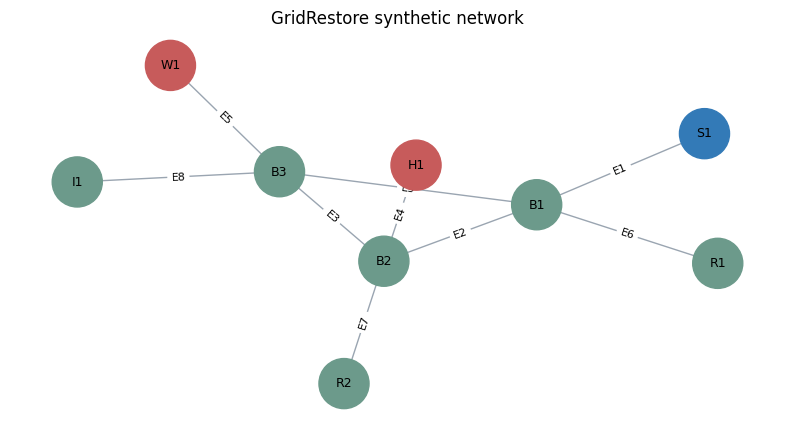

In [4]:
G = nx.Graph()
for r in nodes.to_dict("records"): G.add_node(r["node_id"], **r)
for r in edges.to_dict("records"): G.add_edge(r["from_node_id"],r["to_node_id"],**r)
pos = nx.spring_layout(G,seed=SEED)
plt.figure(figsize=(10,5))
colors = ["#c75b5b" if G.nodes[n]["node_type"] in ("hospital","water_facility") else "#337ab7" if G.nodes[n]["node_type"]=="substation" else "#6c9a8b" for n in G.nodes]
nx.draw_networkx(G,pos,node_color=colors,node_size=1300,font_size=9,edge_color="#9aa5b1")
nx.draw_networkx_edge_labels(G,pos,{(u,v):G.edges[u,v]["edge_id"] for u,v in G.edges},font_size=8)
plt.title("GridRestore synthetic network"); plt.axis("off"); plt.show()

## 4. Scenario and repair tasks

In [5]:
scenario = {"scenario_id":1,"scenario_name":"Synthetic multi-component outage","budget":14000,"crew_count":3}
tasks = pd.DataFrame([
("T01","E1","Feeder E1",3.0,2200,8.0,2,"North"),
("T02","E4","Hospital branch E4",5.0,3600,10.0,1,"Central"),
("T03","E3","South line E3",6.0,4200,9.0,1,"South"),
("T04","E6","Residential feeder E6",2.0,1200,4.0,4,"North"),
("T05","E5","Water facility branch E5",4.0,2800,8.5,2,"South"),
("T06","E8","Industrial feeder E8",3.5,2400,5.0,3,"South"),
("T07","E2","Central line E2",4.5,3000,7.0,2,"Central"),
("T08","E7","Residential feeder E7",2.5,1500,4.5,3,"Central")
],columns=["task_id","edge_id","component_name","estimated_hours","estimated_cost","service_weight","priority","region_code"])
display(pd.DataFrame([scenario])); display(tasks)

,scenario_id,scenario_name,budget,crew_count
0,1,Synthetic multi-component outage,14000,3


,task_id,edge_id,component_name,estimated_hours,estimated_cost,service_weight,priority,region_code
0,T01,E1,Feeder E1,3.0,2200,8.0,2,North
1,T02,E4,Hospital branch E4,5.0,3600,10.0,1,Central
2,T03,E3,South line E3,6.0,4200,9.0,1,South
3,T04,E6,Residential feeder E6,2.0,1200,4.0,4,North
4,T05,E5,Water facility branch E5,4.0,2800,8.5,2,South
5,T06,E8,Industrial feeder E8,3.5,2400,5.0,3,South
6,T07,E2,Central line E2,4.5,3000,7.0,2,Central
7,T08,E7,Residential feeder E7,2.5,1500,4.5,3,Central


## 5. Three scheduling strategies

In [6]:
STRATEGIES = ["priority_first","shortest_repair_first","gridrestore_score"]
def order_tasks(frame,strategy):
    if strategy=="priority_first":
        return frame.sort_values(["priority","service_weight","estimated_hours"],ascending=[True,False,True])
    if strategy=="shortest_repair_first":
        return frame.sort_values(["estimated_hours","priority","service_weight"],ascending=[True,True,False])
    if strategy=="gridrestore_score":
        x=frame.copy()
        x["heuristic_score"]=x["service_weight"]/x["estimated_hours"]+(6-x["priority"])*0.15
        return x.sort_values(["heuristic_score","priority"],ascending=[False,True])
    raise ValueError("Unknown strategy: "+str(strategy))

def schedule_repairs(frame,strategy,budget,crew_count,duration_multiplier=1.0):
    if crew_count<1: raise ValueError("crew_count must be at least 1")
    free=[0.0]*crew_count; actions=[]; spent=0.0; score=0.0
    for t in order_tasks(frame,strategy).to_dict("records"):
        cost=float(t["estimated_cost"])
        if spent+cost>budget: continue
        c=int(np.argmin(free)); start=float(free[c])
        duration=float(t["estimated_hours"])*duration_multiplier; finish=start+duration
        free[c]=finish; spent+=cost
        score+=float(t["service_weight"])/max(finish,0.25)
        actions.append({"task_id":t["task_id"],"component_name":t["component_name"],"crew_id":f"Crew-{c+1}",
          "start_hour":round(start,3),"finish_hour":round(finish,3),"duration_hours":round(duration,3),
          "estimated_cost":cost,"service_weight":float(t["service_weight"]),"priority":int(t["priority"])})
    return {"strategy":strategy,"total_cost":round(spent,2),"makespan_hours":round(max(free),3),
      "weighted_recovery_score":round(score,4),"scheduled_count":len(actions),"actions":actions}

results={s:schedule_repairs(tasks,s,scenario["budget"],scenario["crew_count"]) for s in STRATEGIES}
summary=pd.DataFrame([{k:v for k,v in r.items() if k!="actions"} for r in results.values()])
display(summary.sort_values("weighted_recovery_score",ascending=False))

,strategy,total_cost,makespan_hours,weighted_recovery_score,scheduled_count
1,shortest_repair_first,13100.0,7.5,9.6168,6
2,gridrestore_score,14000.0,10.0,8.4917,5
0,priority_first,14000.0,7.0,7.3393,5


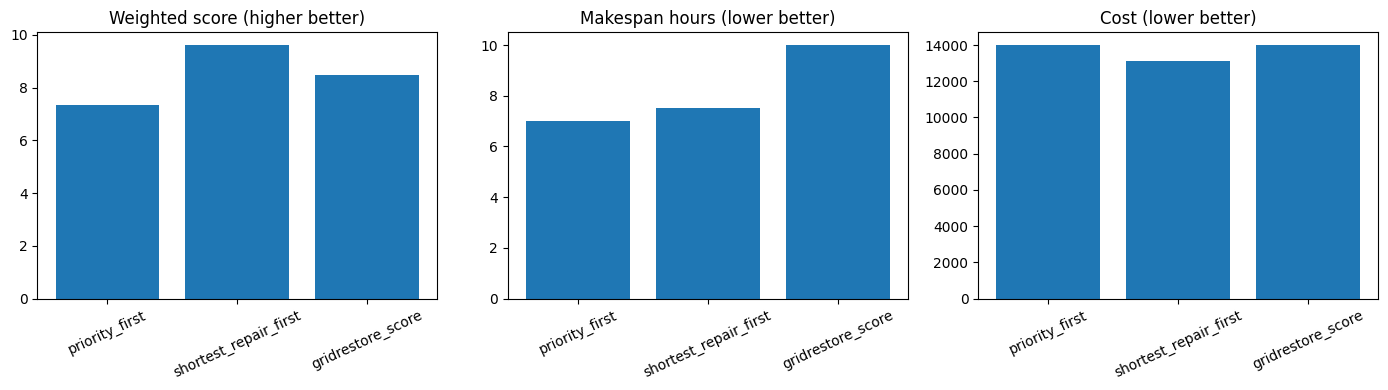

In [7]:
fig,axes=plt.subplots(1,3,figsize=(14,4))
for ax,col,title in zip(axes,["weighted_recovery_score","makespan_hours","total_cost"],
 ["Weighted score (higher better)","Makespan hours (lower better)","Cost (lower better)"]):
    ax.bar(summary["strategy"],summary[col]); ax.set_title(title); ax.tick_params(axis="x",rotation=25)
plt.tight_layout(); plt.show()

## 6. Monte Carlo uncertainty analysis

In [8]:
def monte_carlo(frame,budget,crew_count,trials=300,seed=2026):
    local_rng=np.random.default_rng(seed); rows=[]
    for trial in range(trials):
        multipliers=local_rng.lognormal(mean=0.0,sigma=0.25,size=len(frame))
        sampled=frame.copy()
        sampled["estimated_hours"]=sampled["estimated_hours"].to_numpy()*multipliers
        for strategy in STRATEGIES:
            r=schedule_repairs(sampled,strategy,budget,crew_count)
            rows.append({"trial":trial,"strategy":strategy,"total_cost":r["total_cost"],
              "makespan_hours":r["makespan_hours"],"weighted_recovery_score":r["weighted_recovery_score"],
              "scheduled_count":r["scheduled_count"]})
    return pd.DataFrame(rows)
mc=monte_carlo(tasks,scenario["budget"],scenario["crew_count"])
mc_summary=mc.groupby("strategy").agg(mean_score=("weighted_recovery_score","mean"),
 std_score=("weighted_recovery_score","std"),mean_makespan=("makespan_hours","mean"),
 p90_makespan=("makespan_hours",lambda x:x.quantile(.90)),mean_cost=("total_cost","mean"),
 mean_tasks=("scheduled_count","mean")).reset_index()
display(mc_summary)

,strategy,mean_score,std_score,mean_makespan,p90_makespan,mean_cost,mean_tasks
0,gridrestore_score,9.939759,1.353973,7.821637,9.4472,13432.666667,5.283333
1,priority_first,7.543889,1.000558,7.760263,9.0224,14000.000000,5.000000
2,shortest_repair_first,10.399590,1.277835,7.507243,8.8049,13272.666667,5.910000


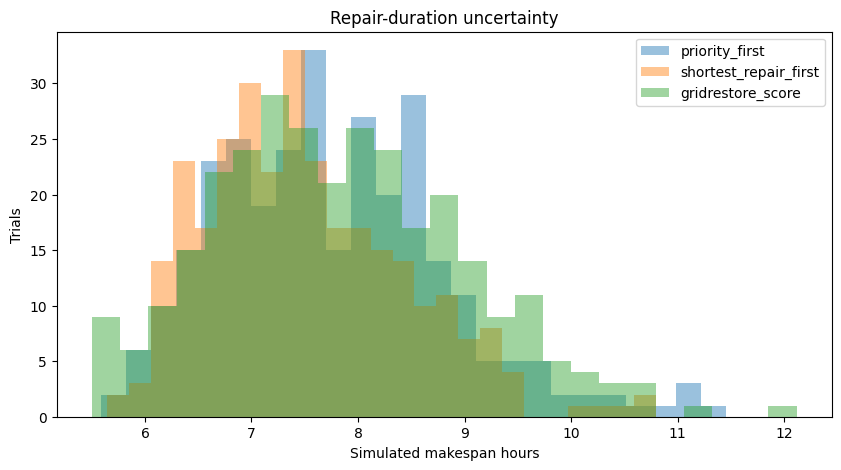

In [9]:
plt.figure(figsize=(10,5))
for s in STRATEGIES: plt.hist(mc.loc[mc.strategy==s,"makespan_hours"],bins=25,alpha=.45,label=s)
plt.xlabel("Simulated makespan hours"); plt.ylabel("Trials"); plt.title("Repair-duration uncertainty"); plt.legend(); plt.show()

## 7. SQLite database demonstration (portable notebook path)

In [10]:
db_path=OUT/"gridrestore_demo.sqlite"
if db_path.exists(): db_path.unlink()
conn=sqlite3.connect(db_path); conn.execute("PRAGMA foreign_keys=ON")
schema = [
"CREATE TABLE grid_nodes(node_id TEXT PRIMARY KEY,node_name TEXT NOT NULL,node_type TEXT NOT NULL,criticality REAL NOT NULL CHECK(criticality BETWEEN 0 AND 10),region_code TEXT NOT NULL)",
"CREATE TABLE grid_edges(edge_id TEXT PRIMARY KEY,from_node_id TEXT NOT NULL REFERENCES grid_nodes(node_id),to_node_id TEXT NOT NULL REFERENCES grid_nodes(node_id),component_type TEXT NOT NULL,nominal_capacity_kw REAL NOT NULL CHECK(nominal_capacity_kw>0),UNIQUE(from_node_id,to_node_id))",
"CREATE TABLE outage_scenarios(scenario_id INTEGER PRIMARY KEY,scenario_name TEXT NOT NULL,budget REAL NOT NULL CHECK(budget>0),crew_count INTEGER NOT NULL CHECK(crew_count>0))",
"CREATE TABLE repair_tasks(task_id TEXT PRIMARY KEY,scenario_id INTEGER NOT NULL REFERENCES outage_scenarios(scenario_id),edge_id TEXT NOT NULL REFERENCES grid_edges(edge_id),component_name TEXT NOT NULL,estimated_hours REAL NOT NULL CHECK(estimated_hours>0),estimated_cost REAL NOT NULL CHECK(estimated_cost>=0),service_weight REAL NOT NULL CHECK(service_weight>=0),priority INTEGER NOT NULL CHECK(priority BETWEEN 1 AND 5),status TEXT NOT NULL DEFAULT 'pending' CHECK(status IN ('pending','scheduled','completed','blocked')))",
"CREATE TABLE restoration_runs(run_id INTEGER PRIMARY KEY AUTOINCREMENT,scenario_id INTEGER NOT NULL REFERENCES outage_scenarios(scenario_id),strategy_name TEXT NOT NULL,total_cost REAL NOT NULL,makespan_hours REAL NOT NULL,weighted_recovery_score REAL NOT NULL)",
"CREATE TABLE scheduled_actions(action_id INTEGER PRIMARY KEY AUTOINCREMENT,run_id INTEGER NOT NULL REFERENCES restoration_runs(run_id),task_id TEXT NOT NULL REFERENCES repair_tasks(task_id),crew_label TEXT NOT NULL,start_hour REAL NOT NULL,finish_hour REAL NOT NULL CHECK(finish_hour>start_hour),UNIQUE(run_id,task_id))",
"CREATE TABLE audit_log(audit_id INTEGER PRIMARY KEY AUTOINCREMENT,table_name TEXT NOT NULL,operation TEXT NOT NULL,row_key TEXT,changed_at TEXT DEFAULT CURRENT_TIMESTAMP)",
"CREATE TRIGGER audit_task_update AFTER UPDATE ON repair_tasks BEGIN INSERT INTO audit_log(table_name,operation,row_key) VALUES('repair_tasks','UPDATE',NEW.task_id); END",
"CREATE VIEW v_restoration_run_summary AS SELECT r.run_id,s.scenario_name,r.strategy_name,r.total_cost,r.makespan_hours,r.weighted_recovery_score,COUNT(a.action_id) AS scheduled_task_count FROM restoration_runs r JOIN outage_scenarios s ON s.scenario_id=r.scenario_id LEFT JOIN scheduled_actions a ON a.run_id=r.run_id GROUP BY r.run_id,s.scenario_name,r.strategy_name,r.total_cost,r.makespan_hours,r.weighted_recovery_score"
]
for statement in schema: conn.execute(statement)
conn.executemany("INSERT INTO grid_nodes VALUES(?,?,?,?,?)",nodes[["node_id","node_name","node_type","criticality","region_code"]].itertuples(index=False,name=None))
conn.executemany("INSERT INTO grid_edges VALUES(?,?,?,?,?)",edges[["edge_id","from_node_id","to_node_id","component_type","nominal_capacity_kw"]].itertuples(index=False,name=None))
conn.execute("INSERT INTO outage_scenarios VALUES(?,?,?,?)",(scenario["scenario_id"],scenario["scenario_name"],scenario["budget"],scenario["crew_count"]))
conn.executemany("INSERT INTO repair_tasks(task_id,scenario_id,edge_id,component_name,estimated_hours,estimated_cost,service_weight,priority,status) VALUES(?,?,?,?,?,?,?,?,?)",
 [(r.task_id,scenario["scenario_id"],r.edge_id,r.component_name,r.estimated_hours,r.estimated_cost,r.service_weight,r.priority,"pending") for r in tasks.itertuples(index=False)])
conn.commit()
print("SQLite demo database:",db_path.resolve())

SQLite demo database: C:\Users\Prabha Prabhu\OneDrive\Desktop\GridRestore\notebook\gridrestore_outputs\gridrestore_demo.sqlite


## 8. Persist each run transactionally and query results

In [11]:
def persist_result(connection,scenario_id,result):
    with connection:
        cur=connection.execute("INSERT INTO restoration_runs(scenario_id,strategy_name,total_cost,makespan_hours,weighted_recovery_score) VALUES(?,?,?,?,?)",
          (scenario_id,result["strategy"],result["total_cost"],result["makespan_hours"],result["weighted_recovery_score"]))
        run_id=cur.lastrowid
        connection.executemany("INSERT INTO scheduled_actions(run_id,task_id,crew_label,start_hour,finish_hour) VALUES(?,?,?,?,?)",
          [(run_id,a["task_id"],a["crew_id"],a["start_hour"],a["finish_hour"]) for a in result["actions"]])
    return run_id
run_ids={s:persist_result(conn,scenario["scenario_id"],r) for s,r in results.items()}
display(pd.read_sql_query("SELECT * FROM v_restoration_run_summary ORDER BY weighted_recovery_score DESC",conn))
sql = "SELECT strategy_name,COUNT(*) AS runs,ROUND(AVG(total_cost),2) AS avg_cost,ROUND(AVG(makespan_hours),2) AS avg_makespan,ROUND(AVG(weighted_recovery_score),4) AS avg_score FROM restoration_runs GROUP BY strategy_name HAVING COUNT(*)>=1 ORDER BY avg_score DESC"
display(pd.read_sql_query(sql,conn))

,run_id,scenario_name,strategy_name,total_cost,makespan_hours,weighted_recovery_score,scheduled_task_count
0,2,Synthetic multi-component outage,shortest_repair_first,13100.0,7.5,9.6168,6
1,3,Synthetic multi-component outage,gridrestore_score,14000.0,10.0,8.4917,5
2,1,Synthetic multi-component outage,priority_first,14000.0,7.0,7.3393,5


,strategy_name,runs,avg_cost,avg_makespan,avg_score
0,shortest_repair_first,1,13100.0,7.5,9.6168
1,gridrestore_score,1,14000.0,10.0,8.4917
2,priority_first,1,14000.0,7.0,7.3393


In [12]:
conn.execute("UPDATE repair_tasks SET status='scheduled' WHERE task_id='T01'"); conn.commit()
display(pd.read_sql_query("SELECT * FROM audit_log ORDER BY audit_id DESC",conn))
assert len(pd.read_sql_query("SELECT * FROM audit_log",conn))>0
print("Audit trigger passed.")

,audit_id,table_name,operation,row_key,changed_at
0,1,repair_tasks,UPDATE,T01,2026-10-17 13:28:16


Audit trigger passed.


## 9. Validation checks

In [13]:
assert nodes.node_id.is_unique and edges.edge_id.is_unique and tasks.task_id.is_unique
assert set(edges.from_node_id).issubset(set(nodes.node_id))
assert set(edges.to_node_id).issubset(set(nodes.node_id))
for strategy,r in results.items():
    assert r["total_cost"]<=scenario["budget"]
    assert r["scheduled_count"]==len(r["actions"])
    assert all(a["finish_hour"]>a["start_hour"] for a in r["actions"])
assert len(mc)==300*len(STRATEGIES)
assert pd.read_sql_query("PRAGMA foreign_key_check",conn).empty
print("All validation checks passed.")

All validation checks passed.


## 10. Export results and report

In [14]:
nodes.to_csv(OUT/"grid_nodes.csv",index=False); edges.to_csv(OUT/"grid_edges.csv",index=False)
tasks.to_csv(OUT/"repair_tasks.csv",index=False); summary.to_csv(OUT/"deterministic_summary.csv",index=False)
mc.to_csv(OUT/"monte_carlo_trials.csv",index=False); mc_summary.to_csv(OUT/"monte_carlo_summary.csv",index=False)
best_det=summary.sort_values("weighted_recovery_score",ascending=False).iloc[0]
best_mc=mc_summary.sort_values("mean_score",ascending=False).iloc[0]
report=f'''# GridRestore experiment report

- Scenario: {scenario["scenario_name"]}
- Budget: {scenario["budget"]} synthetic credits
- Crews: {scenario["crew_count"]}
- Tasks: {len(tasks)}
- Deterministic best score: {best_det["strategy"]} ({best_det["weighted_recovery_score"]})
- Monte Carlo best mean score: {best_mc["strategy"]} ({best_mc["mean_score"]:.4f})
- Mean makespan for that strategy: {best_mc["mean_makespan"]:.2f} hours

## Limitations
Synthetic data and project-defined metrics only. Greedy algorithms are not guaranteed optimal. Repair prerequisites, crew skills, validated power-flow physics and real utility data are not modeled.
'''
(OUT/"experiment_report.md").write_text(report,encoding="utf-8")
print(report)
print("Outputs in",OUT.resolve())

# GridRestore experiment report

- Scenario: Synthetic multi-component outage
- Budget: 14000 synthetic credits
- Crews: 3
- Tasks: 8
- Deterministic best score: shortest_repair_first (9.6168)
- Monte Carlo best mean score: shortest_repair_first (10.3996)
- Mean makespan for that strategy: 7.51 hours

## Limitations
Synthetic data and project-defined metrics only. Greedy algorithms are not guaranteed optimal. Repair prerequisites, crew skills, validated power-flow physics and real utility data are not modeled.

Outputs in C:\Users\Prabha Prabhu\OneDrive\Desktop\GridRestore\notebook\gridrestore_outputs


## 11. Next steps
- Connect the dependency- and crew-skill-aware backend scheduler to the Streamlit UI and persist runs/actions.
- Verify the complete PostgreSQL workflow against a running database.
- Compare the greedy strategies with an exact optimization baseline on small synthetic instances.
- Run `EXPLAIN ANALYZE` and record database performance on a documented test dataset.
- If standards mapping is required, review exact official editions and map only relevant requirements to tests; do not claim compliance.
